In [1]:
import torch
from helper_lib.assignment3_gan import MNISTGAN

In [2]:
device = torch.device(
    "mps" if torch.backends.mps.is_available()
    else "cuda" if torch.cuda.is_available()
    else "cpu"
)

In [3]:
gan = MNISTGAN(latent_dim=100).to(device)
gan.eval()

noise = torch.randn(4, 100, device=device)

with torch.no_grad():
    generated_images = gan(noise)
    probabilities = gan.discriminator(generated_images)

print("Using device:", device)
print("Noise shape:", noise.shape)
print("Generated images shape:", generated_images.shape)
print("Discriminator output shape:", probabilities.shape)
print("Pixel min:", generated_images.min().item())
print("Pixel max:", generated_images.max().item())


Using device: mps
Noise shape: torch.Size([4, 100])
Generated images shape: torch.Size([4, 1, 28, 28])
Discriminator output shape: torch.Size([4, 1])
Pixel min: -0.8010045886039734
Pixel max: 0.6526156067848206


In [4]:
assert generated_images.shape == (4, 1, 28, 28)
assert probabilities.shape == (4, 1)
assert torch.all((probabilities >= 0) & (probabilities <= 1))

print("Architecture checks passed.")

Architecture checks passed.


In [5]:
# Load MNIST training data
import importlib
import helper_lib.data_loader as data_module

importlib.reload(data_module)

train_loader = data_module.get_mnist_gan_data_loader(
    "./data",
    batch_size=64,
)

real_images, labels = next(iter(train_loader))

print("Training images:", len(train_loader.dataset))
print("Batch shape:", real_images.shape)
print("Labels shape:", labels.shape)
print("Pixel min:", real_images.min().item())
print("Pixel max:", real_images.max().item())

assert real_images.shape == (64, 1, 28, 28)
assert real_images.min().item() >= -1.0
assert real_images.max().item() <= 1.0

print("MNIST data checks passed.")

100%|██████████| 9.91M/9.91M [00:00<00:00, 10.6MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 2.69MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 14.8MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 1.59MB/s]


Training images: 60000
Batch shape: torch.Size([64, 1, 28, 28])
Labels shape: torch.Size([64])
Pixel min: -1.0
Pixel max: 1.0
MNIST data checks passed.


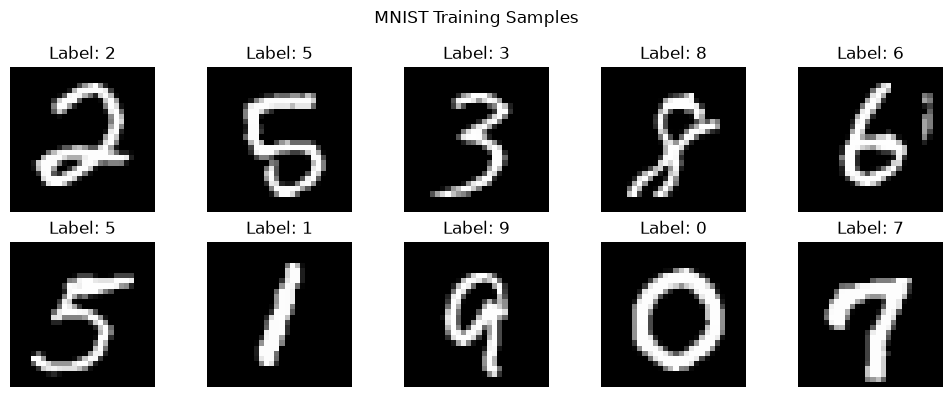

In [6]:
# Check first 10 images
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for index, ax in enumerate(axes.flat):
    image = (real_images[index, 0] + 1) / 2
    ax.imshow(image.numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Label: {labels[index].item()}")
    ax.axis("off")

fig.suptitle("MNIST Training Samples")
plt.tight_layout()
plt.show()

In [7]:
from helper_lib.assignment3_gan import MNISTGAN
from helper_lib.assignment3_trainer import train_mnist_gan

torch.manual_seed(42)

gan = MNISTGAN(latent_dim=100).to(device)

generator_optimizer = torch.optim.Adam(
    gan.generator.parameters(),
    lr=0.0002,
    betas=(0.5, 0.999),
)

discriminator_optimizer = torch.optim.Adam(
    gan.discriminator.parameters(),
    lr=0.0002,
    betas=(0.5, 0.999),
)

fixed_noise = torch.randn(16, gan.latent_dim, device=device)
training_history = []

print("Training setup ready.")

Training setup ready.


In [8]:
epoch_history = train_mnist_gan(
    gan=gan,
    data_loader=train_loader,
    generator_optimizer=generator_optimizer,
    discriminator_optimizer=discriminator_optimizer,
    device=device,
    epochs=1,
)

training_history.extend(epoch_history)

Epoch 1/1 | Batch 200/938 | D loss: 0.3594 | G loss: 0.6406
Epoch 1/1 | Batch 400/938 | D loss: 0.1055 | G loss: 2.7959
Epoch 1/1 | Batch 600/938 | D loss: 0.0945 | G loss: 2.7952
Epoch 1/1 | Batch 800/938 | D loss: 0.1100 | G loss: 2.6990
Epoch 1/1 | Batch 938/938 | D loss: 0.1264 | G loss: 3.4275
Epoch 1/1 complete | Mean D loss: 0.1545 | Mean G loss: 2.5519


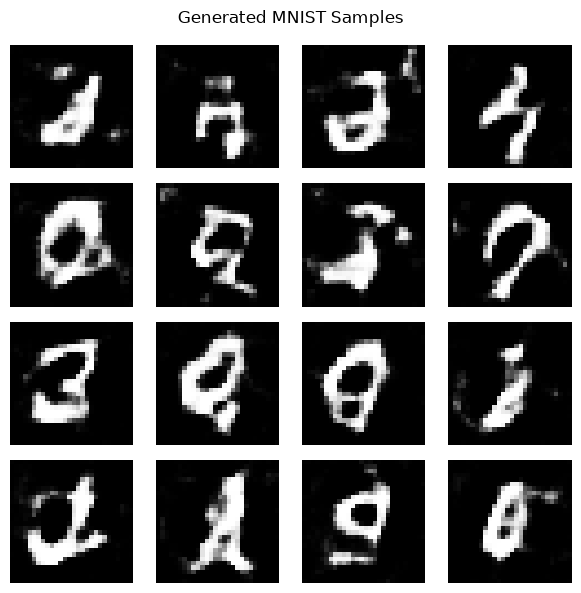

In [9]:
gan.eval()

with torch.no_grad():
    generated_images = gan.generator(fixed_noise).cpu()

display_images = ((generated_images + 1) / 2).clamp(0, 1)

fig, axes = plt.subplots(4, 4, figsize=(6, 6))

for index, ax in enumerate(axes.flat):
    ax.imshow(
        display_images[index, 0].numpy(),
        cmap="gray",
        vmin=0,
        vmax=1,
    )
    ax.axis("off")

fig.suptitle("Generated MNIST Samples")
plt.tight_layout()
plt.show()

In [10]:
epoch_history = train_mnist_gan(
    gan=gan,
    data_loader=train_loader,
    generator_optimizer=generator_optimizer,
    discriminator_optimizer=discriminator_optimizer,
    device=device,
    epochs=4,
)

training_history.extend(epoch_history)

print("Total completed epochs:", len(training_history))

Epoch 1/4 | Batch 200/938 | D loss: 0.8279 | G loss: 6.9284
Epoch 1/4 | Batch 400/938 | D loss: 0.1340 | G loss: 2.4526
Epoch 1/4 | Batch 600/938 | D loss: 0.1340 | G loss: 3.1965
Epoch 1/4 | Batch 800/938 | D loss: 0.0996 | G loss: 3.0419
Epoch 1/4 | Batch 938/938 | D loss: 0.1105 | G loss: 2.8298
Epoch 1/4 complete | Mean D loss: 0.1459 | Mean G loss: 2.8016
Epoch 2/4 | Batch 200/938 | D loss: 0.1084 | G loss: 2.6411
Epoch 2/4 | Batch 400/938 | D loss: 0.1413 | G loss: 3.2803
Epoch 2/4 | Batch 600/938 | D loss: 0.1830 | G loss: 2.8434
Epoch 2/4 | Batch 800/938 | D loss: 0.1170 | G loss: 2.7565
Epoch 2/4 | Batch 938/938 | D loss: 0.2168 | G loss: 2.8984
Epoch 2/4 complete | Mean D loss: 0.1648 | Mean G loss: 2.7587
Epoch 3/4 | Batch 200/938 | D loss: 0.1232 | G loss: 2.3992
Epoch 3/4 | Batch 400/938 | D loss: 0.1111 | G loss: 3.6174
Epoch 3/4 | Batch 600/938 | D loss: 0.2339 | G loss: 4.2439
Epoch 3/4 | Batch 800/938 | D loss: 0.0991 | G loss: 2.8672
Epoch 3/4 | Batch 938/938 | D loss

In [12]:
from pathlib import Path

models_dir = Path("models")
results_dir = Path("assignment3_results")

models_dir.mkdir(parents=True, exist_ok=True)
results_dir.mkdir(parents=True, exist_ok=True)

checkpoint_path = models_dir / "assignment3_mnist_gan.pth"

checkpoint = {
    "model_state_dict": {
        name: tensor.detach().cpu()
        for name, tensor in gan.state_dict().items()
    },
    "latent_dim": gan.latent_dim,
    "epochs_completed": len(training_history),
    "training_history": training_history,
}

torch.save(checkpoint, checkpoint_path)

figure_path = results_dir / "mnist_generated_samples.png"
fig.savefig(figure_path, dpi=150, bbox_inches="tight")

print("Checkpoint saved to:", checkpoint_path)
print("Checkpoint exists:", checkpoint_path.is_file())
print("Completed epochs:", len(training_history))
print("Sample figure saved to:", figure_path)

Checkpoint saved to: models/assignment3_mnist_gan.pth
Checkpoint exists: True
Completed epochs: 5
Sample figure saved to: assignment3_results/mnist_generated_samples.png


Completed epochs: 5


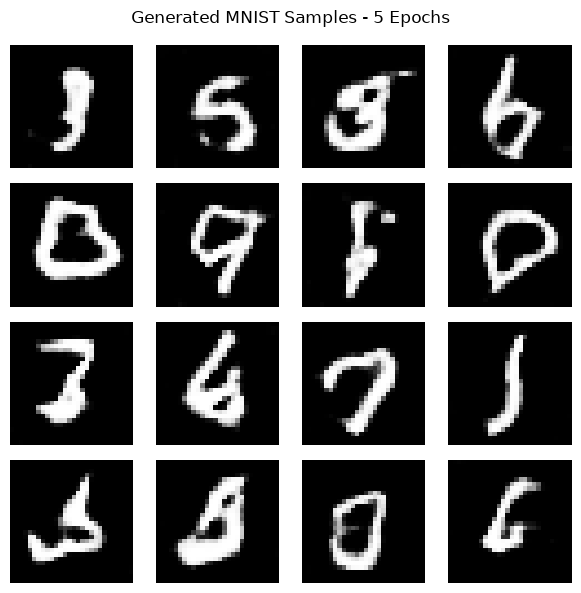

Figure saved to: assignment3_results/mnist_generated_samples.png


In [13]:
from pathlib import Path
import matplotlib.pyplot as plt
import torch

print("Completed epochs:", len(training_history))

gan.eval()

with torch.no_grad():
    samples = gan.generator(fixed_noise).cpu()

samples = ((samples + 1) / 2).clamp(0, 1)

fig, axes = plt.subplots(4, 4, figsize=(6, 6))

for index, ax in enumerate(axes.flat):
    ax.imshow(
        samples[index, 0].numpy(),
        cmap="gray",
        vmin=0,
        vmax=1,
    )
    ax.axis("off")

fig.suptitle(
    f"Generated MNIST Samples - {len(training_history)} Epochs"
)
fig.tight_layout()

output_path = Path("assignment3_results/mnist_generated_samples.png")
output_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(output_path, dpi=150, bbox_inches="tight")

plt.show()
print("Figure saved to:", output_path)

In [ ]:
from pathlib import Path

checkpoint_path = Path("models/assignment3_mnist_gan.pth")
checkpoint_path.parent.mkdir(parents=True, exist_ok=True)

torch.save(
    {
        "model_state_dict": {
            name: tensor.detach().cpu()
            for name, tensor in gan.state_dict().items()
        },
        "latent_dim": gan.latent_dim,
        "epochs_completed": len(training_history),
        "training_history": training_history,
    },
    checkpoint_path,
)

print("Saved checkpoint:", checkpoint_path)
print("Completed epochs:", len(training_history))

In [14]:
from pathlib import Path

checkpoint_path = Path("models/assignment3_mnist_gan.pth")
checkpoint_path.parent.mkdir(parents=True, exist_ok=True)

torch.save(
    {
        "model_state_dict": {
            name: tensor.detach().cpu()
            for name, tensor in gan.state_dict().items()
        },
        "latent_dim": gan.latent_dim,
        "epochs_completed": len(training_history),
        "training_history": training_history,
    },
    checkpoint_path,
)

print("Saved checkpoint:", checkpoint_path)
print("Completed epochs:", len(training_history))

Saved checkpoint: models/assignment3_mnist_gan.pth
Completed epochs: 5


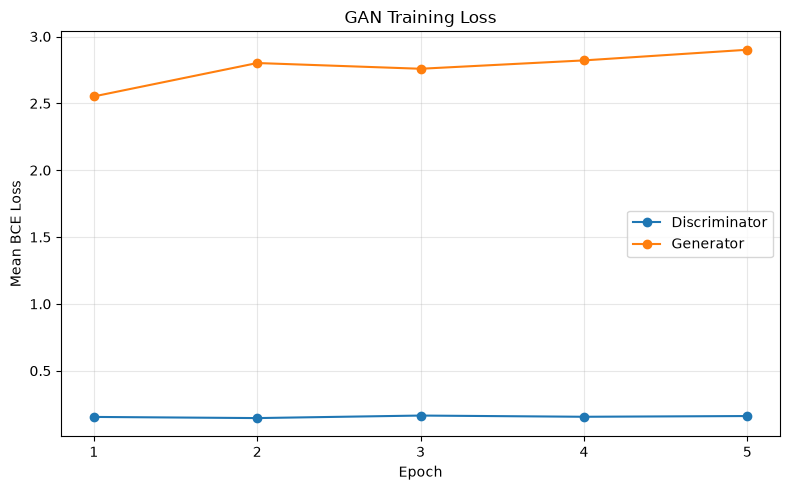

In [16]:
import matplotlib.pyplot as plt

epochs = range(1, len(training_history) + 1)

d_losses = [
    entry["discriminator_loss"]
    for entry in training_history
]

g_losses = [
    entry["generator_loss"]
    for entry in training_history
]

loss_fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(epochs, d_losses, marker="o", label="Discriminator")
ax.plot(epochs, g_losses, marker="o", label="Generator")

ax.set_xlabel("Epoch")
ax.set_ylabel("Mean BCE Loss")
ax.set_title("GAN Training Loss")
ax.set_xticks(list(epochs))
ax.legend()
ax.grid(alpha=0.3)

loss_fig.tight_layout()
loss_fig.savefig(
    "assignment3_results/training_loss.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()